# Matrix Factorization SVD


## 0 — Imports & Data

In [1]:
from surprise import Dataset, SVD, accuracy, model_selection, Reader

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split


In [2]:
path = "/Users/apple/quantum machine learning/Q-prior/data/ml-100k"

ratings = pd.read_csv(
    f"{path}/u.data",
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"]
)

print(f"Ratings: {len(ratings):,}")
print(f"Users:   {ratings['user_id'].nunique()}")
print(f"Movies:  {ratings['item_id'].nunique()}")
print(f"Mean rating: {ratings['rating'].mean():.4f}")

ratings.head()


Ratings: 100,000
Users:   943
Movies:  1682
Mean rating: 3.5299


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [3]:
#  Index maps for PyTorch
user_ids  = ratings["user_id"].unique()
movie_ids = ratings["item_id"].unique()

user_to_idx  = {u: i for i, u in enumerate(user_ids)}
movie_to_idx = {m: i for i, m in enumerate(movie_ids)}

ratings["user_idx"]  = ratings["user_id"].map(user_to_idx)
ratings["movie_idx"] = ratings["item_id"].map(movie_to_idx)

n_users  = len(user_ids)
n_movies = len(movie_ids)
global_mean = float(ratings["rating"].mean())

# Shared train/test split
train_df, test_df = train_test_split(ratings, test_size=0.2, random_state=42)

# PyTorch tensors
train_users   = torch.tensor(train_df["user_idx"].values,  dtype=torch.long)
train_movies  = torch.tensor(train_df["movie_idx"].values, dtype=torch.long)
train_ratings = torch.tensor(train_df["rating"].values,    dtype=torch.float32)

test_users    = torch.tensor(test_df["user_idx"].values,   dtype=torch.long)
test_movies   = torch.tensor(test_df["movie_idx"].values,  dtype=torch.long)
test_ratings  = torch.tensor(test_df["rating"].values,     dtype=torch.float32)

print("Train size:", len(train_df))
print("Test size: ", len(test_df))


Train size: 80000
Test size:  20000


## I — Data 

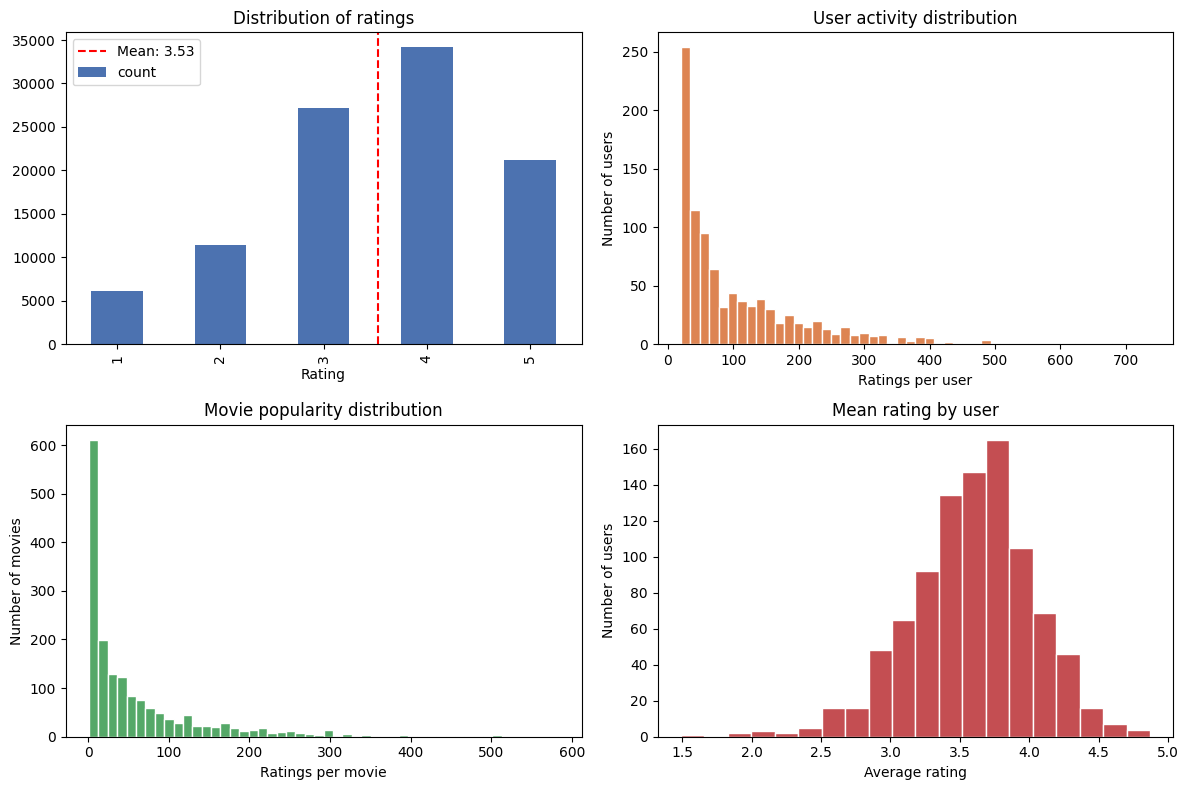

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Rating distribution
ax = axes[0, 0]
ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=ax, color="#4C72B0")
ax.axvline(ratings["rating"].mean() - 1, color="red", linestyle="--",
           label=f'Mean: {ratings["rating"].mean():.2f}')
ax.set_title("Distribution of ratings")
ax.set_xlabel("Rating")
ax.legend()

# User activity
ax = axes[0, 1]
user_activity = ratings.groupby("user_id").size()
ax.hist(user_activity, bins=50, color="#DD8452", edgecolor="white")
ax.set_title("User activity distribution")
ax.set_xlabel("Ratings per user")
ax.set_ylabel("Number of users")

# Movie popularity
ax = axes[1, 0]
movie_popularity = ratings.groupby("item_id").size()
ax.hist(movie_popularity, bins=50, color="#55A868", edgecolor="white")
ax.set_title("Movie popularity distribution")
ax.set_xlabel("Ratings per movie")
ax.set_ylabel("Number of movies")

# Mean rating per user
ax = axes[1, 1]
user_mean = ratings.groupby("user_id")["rating"].mean()
ax.hist(user_mean, bins=20, color="#C44E52", edgecolor="white")
ax.set_title("Mean rating by user")
ax.set_xlabel("Average rating")
ax.set_ylabel("Number of users")

plt.tight_layout()
plt.show()


---
## II — Model I: Surprise SVD

Surprise's built-in SVD implements biased matrix factorisation:

$$\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$$




In [5]:
reader = Reader(rating_scale=(1, 5))

train_data = Dataset.load_from_df(
    train_df[["user_id", "item_id", "rating"]],
    reader
)

trainset_s = train_data.build_full_trainset()

testset_s = list(
    test_df[["user_id", "item_id", "rating"]]
    .itertuples(index=False, name=None)
)


model_surprise = SVD(
    n_factors=50,
    n_epochs=30,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)

model_surprise.fit(trainset_s)
predictions_s = model_surprise.test(testset_s)

rmse_surprise = accuracy.rmse(predictions_s)
mae_surprise  = accuracy.mae(predictions_s)
print(f"Surprise SVD  →  RMSE: {rmse_surprise:.4f}  MAE: {mae_surprise:.4f}")


RMSE: 0.9355
MAE:  0.7345
Surprise SVD  →  RMSE: 0.9355  MAE: 0.7345


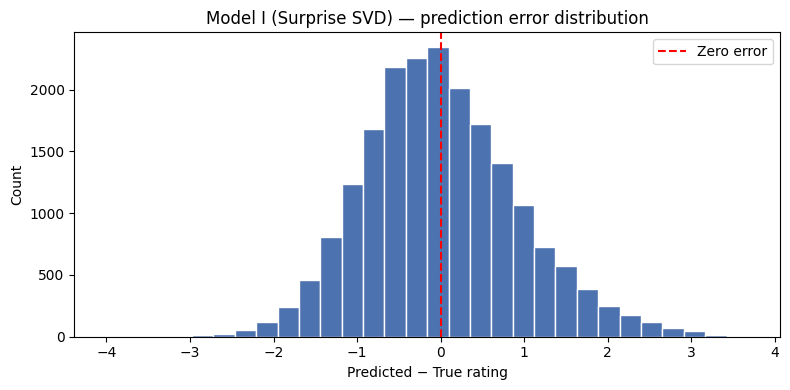

In [6]:
# Error distribution
pred_df = pd.DataFrame(predictions_s)
pred_df["error"] = pred_df["est"] - pred_df["r_ui"]

plt.figure(figsize=(8, 4))
plt.hist(pred_df["error"], bins=30, color="#4C72B0", edgecolor="white")
plt.axvline(0, color="red", linestyle="--", label="Zero error")
plt.xlabel("Predicted − True rating")
plt.ylabel("Count")
plt.title("Model I (Surprise SVD) — prediction error distribution")
plt.legend()
plt.tight_layout()
plt.show()


---
## III — Model II: PyTorch SVD


$$\mathcal{L} = \sum_{(u,i)\in\kappa}(r_{ui}-\hat r_{ui})^2 + \lambda\left(\|p_u\|^2+\|q_i\|^2+b_u^2+b_i^2\right)$$

**Reference:** Y. Koren, R. Bell, and C. Volinsky, *Matrix Factorization Techniques for Recommender Systems*, Computer, 2009. DOI: https://doi.org/10.1109/MC.2009.263


In [7]:
class MatrixFactorization(nn.Module):
    """
    Biased Matrix Factorisation — mirrors Surprise SVD exactly.

    Formula:  r_hat = mu + b_u + b_i + p_u · q_i

    Parameters
    ----------
    n_users     : number of unique users  → rows of P
    n_movies    : number of unique movies → rows of Q
    n_factors   : latent dimension k
    rating_mean : dataset mean, used to fix global bias mu
    """

    def __init__(self, n_users, n_movies, n_factors=50, rating_mean=train_df["rating"].mean()):
        super().__init__()

        # P — user latent factors
        self.user_factors  = nn.Embedding(n_users,  n_factors)
        # Q — item latent factors
        self.movie_factors = nn.Embedding(n_movies, n_factors)

        # b_u —  user bias
        self.user_bias  = nn.Embedding(n_users,  1)

        # b_i — item bias
        self.movie_bias = nn.Embedding(n_movies, 1)

        # mu — global mean rating, fixed
        self.register_buffer("global_bias", torch.tensor(rating_mean, dtype=torch.float32))

        # small random init for factors, zero for biases
        nn.init.normal_(self.user_factors.weight,  std=0.01)
        nn.init.normal_(self.movie_factors.weight, std=0.01)
        nn.init.zeros_(self.user_bias.weight)
        nn.init.zeros_(self.movie_bias.weight)

    def forward(self, users, movies):
        p_u = self.user_factors(users)
        q_i = self.movie_factors(movies)

        dot = (p_u * q_i).sum(dim=1)

        b_u = self.user_bias(users).squeeze(-1)
        b_i = self.movie_bias(movies).squeeze(-1)

        # r_hat = mu + b_u + b_i + p_u · q_i
        return self.global_bias + b_u + b_i + dot


In [8]:
def explicit_loss(pred, target, model, users, movies, lam=0.02):
    """
    Regularised MSE — explicit version of Surprise's internal objective.

    L = (1/N) * sum((r - r_hat)^2) + lambda * (||p_u||^2 + ||q_i||^2 + b_u^2 + b_i^2)
    """
    # reconstruction error
    mse = ((pred - target) ** 2).mean()

    # regularisation term
    p_u = model.user_factors(users)
    q_i = model.movie_factors(movies)
    b_u = model.user_bias(users).squeeze(-1)
    b_i = model.movie_bias(movies).squeeze(-1)

    reg = lam * (
        (p_u ** 2).mean() +
        (q_i ** 2).mean() +
        (b_u ** 2).mean() +
        (b_i ** 2).mean()
    )

    return mse + reg


In [9]:
# Train
model_pytorch = MatrixFactorization(
    n_users, n_movies,
    n_factors=50,
    rating_mean=global_mean
)

# optimizer = torch.optim.SGD(model_pytorch.parameters(), lr=0.005)
optimizer = torch.optim.Adam(model_pytorch.parameters(), lr=0.001)
epochs = 180
lam    = 0.002

for epoch in range(epochs):
    model_pytorch.train()
    optimizer.zero_grad()

    preds = model_pytorch(train_users, train_movies)
    loss  = explicit_loss(preds, train_ratings, model_pytorch,
                          train_users, train_movies, lam=lam)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1:3d}/{epochs} | Loss: {loss.item():.4f}")


Epoch   5/180 | Loss: 1.2613
Epoch  10/180 | Loss: 1.2524
Epoch  15/180 | Loss: 1.2427
Epoch  20/180 | Loss: 1.2318
Epoch  25/180 | Loss: 1.2195
Epoch  30/180 | Loss: 1.2054
Epoch  35/180 | Loss: 1.1892
Epoch  40/180 | Loss: 1.1708
Epoch  45/180 | Loss: 1.1501
Epoch  50/180 | Loss: 1.1272
Epoch  55/180 | Loss: 1.1022
Epoch  60/180 | Loss: 1.0753
Epoch  65/180 | Loss: 1.0470
Epoch  70/180 | Loss: 1.0178
Epoch  75/180 | Loss: 0.9880
Epoch  80/180 | Loss: 0.9583
Epoch  85/180 | Loss: 0.9290
Epoch  90/180 | Loss: 0.9005
Epoch  95/180 | Loss: 0.8730
Epoch 100/180 | Loss: 0.8466
Epoch 105/180 | Loss: 0.8215
Epoch 110/180 | Loss: 0.7976
Epoch 115/180 | Loss: 0.7748
Epoch 120/180 | Loss: 0.7530
Epoch 125/180 | Loss: 0.7321
Epoch 130/180 | Loss: 0.7122
Epoch 135/180 | Loss: 0.6929
Epoch 140/180 | Loss: 0.6744
Epoch 145/180 | Loss: 0.6565
Epoch 150/180 | Loss: 0.6392
Epoch 155/180 | Loss: 0.6223
Epoch 160/180 | Loss: 0.6060
Epoch 165/180 | Loss: 0.5901
Epoch 170/180 | Loss: 0.5747
Epoch 175/180 

In [10]:
# Evaluate
model_pytorch.eval()
with torch.no_grad():
    test_preds_pt = model_pytorch(test_users, test_movies)
    rmse_pytorch  = torch.sqrt(((test_preds_pt - test_ratings) ** 2).mean()).item()

print(f"Model II (PyTorch)  →  RMSE: {rmse_pytorch:.4f}")
print(f"Model I  (Surprise) →  RMSE: {rmse_surprise:.4f}")


Model II (PyTorch)  →  RMSE: 0.9399
Model I  (Surprise) →  RMSE: 0.9355


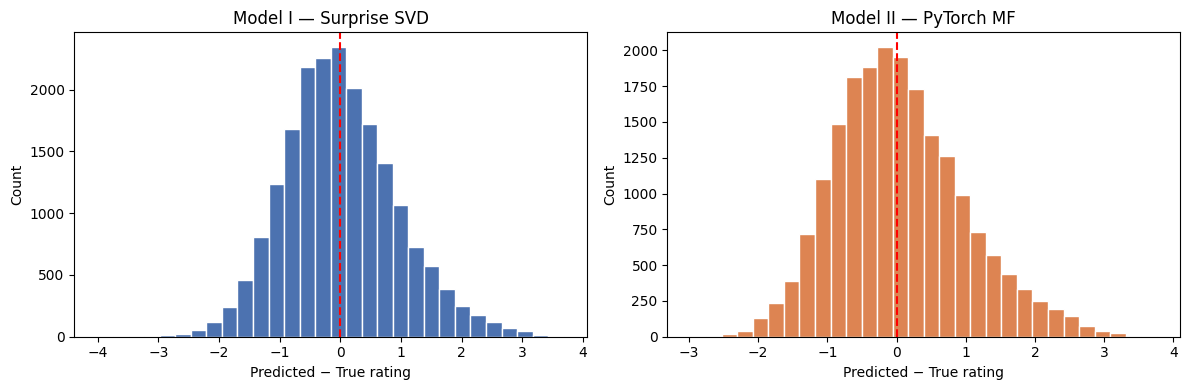

In [11]:
# Error distribution comparison
pt_errors = (test_preds_pt - test_ratings).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, errors, title, color in zip(
    axes,
    [pred_df["error"].values, pt_errors],
    ["Model I — Surprise SVD", "Model II — PyTorch MF"],
    ["#4C72B0", "#DD8452"]
):
    ax.hist(errors, bins=30, color=color, edgecolor="white")
    ax.axvline(0, color="red", linestyle="--")
    ax.set_xlabel("Predicted − True rating")
    ax.set_ylabel("Count")
    ax.set_title(title)

plt.tight_layout()
plt.show()


## IV- SVD with MSE as Loss

$$\mathcal{L} = \sum_{(u,i)\in\kappa}(r_{ui}-\hat r_{ui})^2$$


In [12]:
model = MatrixFactorization(
    n_users,
    n_movies,
    n_factors=50,
    rating_mean=train_df["rating"].mean()
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 185

loss_fn = nn.MSELoss()

for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    preds = model(train_users, train_movies)

    loss = loss_fn(preds, train_ratings)

    loss.backward()
    optimizer.step()

    if epoch % 5 == 0:
        print(f"Epoch {epoch:3d} | Loss = {loss.item():.4f}")

Epoch   0 | Loss = 1.2681
Epoch   5 | Loss = 1.2596
Epoch  10 | Loss = 1.2505
Epoch  15 | Loss = 1.2405
Epoch  20 | Loss = 1.2292
Epoch  25 | Loss = 1.2162
Epoch  30 | Loss = 1.2012
Epoch  35 | Loss = 1.1840
Epoch  40 | Loss = 1.1644
Epoch  45 | Loss = 1.1425
Epoch  50 | Loss = 1.1184
Epoch  55 | Loss = 1.0923
Epoch  60 | Loss = 1.0648
Epoch  65 | Loss = 1.0362
Epoch  70 | Loss = 1.0071
Epoch  75 | Loss = 0.9781
Epoch  80 | Loss = 0.9496
Epoch  85 | Loss = 0.9220
Epoch  90 | Loss = 0.8954
Epoch  95 | Loss = 0.8700
Epoch 100 | Loss = 0.8457
Epoch 105 | Loss = 0.8224
Epoch 110 | Loss = 0.8002
Epoch 115 | Loss = 0.7788
Epoch 120 | Loss = 0.7582
Epoch 125 | Loss = 0.7384
Epoch 130 | Loss = 0.7193
Epoch 135 | Loss = 0.7008
Epoch 140 | Loss = 0.6828
Epoch 145 | Loss = 0.6654
Epoch 150 | Loss = 0.6484
Epoch 155 | Loss = 0.6319
Epoch 160 | Loss = 0.6158
Epoch 165 | Loss = 0.6002
Epoch 170 | Loss = 0.5849
Epoch 175 | Loss = 0.5699
Epoch 180 | Loss = 0.5553


In [13]:
# Evaluate
model.eval()
with torch.no_grad():
    mse_test_preds = model(test_users, test_movies)
    mse_rmse = torch.sqrt(((mse_test_preds - test_ratings) ** 2).mean())

print(f"Model III (MSE)  →  RMSE: {mse_rmse:.4f}")
print(f"Model II (regularized loss)  →  RMSE: {rmse_pytorch:.4f}")
print(f"Model I  (Surprise) →  RMSE: {rmse_surprise:.4f}")

Model III (MSE)  →  RMSE: 0.9375
Model II (regularized loss)  →  RMSE: 0.9399
Model I  (Surprise) →  RMSE: 0.9355


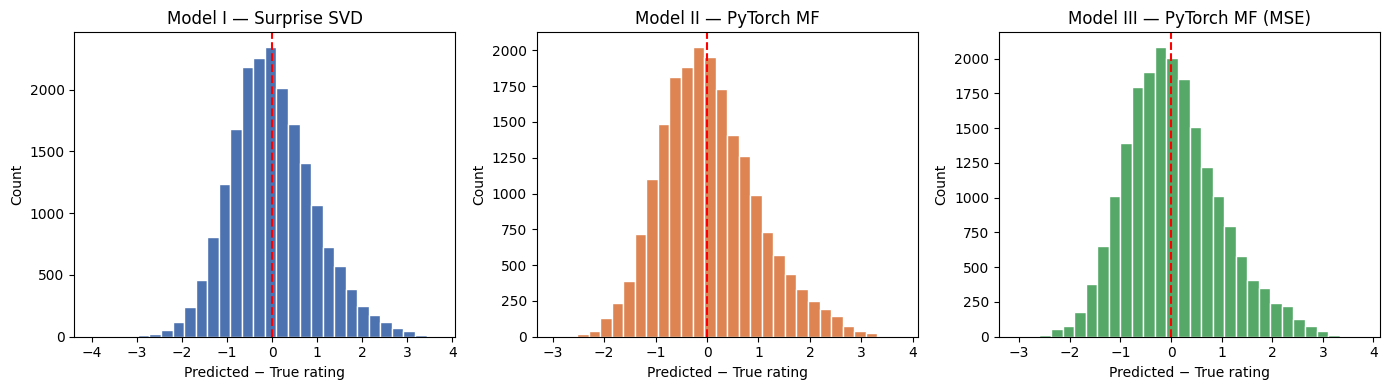

In [14]:
# Error distribution comparison
mse_errors = (mse_test_preds - test_ratings).numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, errors, title, color in zip(

    axes,
    [pred_df["error"].values,pt_errors, mse_errors],
    ["Model I — Surprise SVD", "Model II — PyTorch MF", "Model III — PyTorch MF (MSE)"],
    ["#4C72B0", "#DD8452", "#55A868"]
):
    ax.hist(errors, bins=30, color=color, edgecolor="white")
    ax.axvline(0, color="red", linestyle="--")
    ax.set_xlabel("Predicted − True rating")
    ax.set_ylabel("Count")
    ax.set_title(title)

plt.tight_layout()
plt.show()



---
## IV-B — Model IV: PyTorch SVD + Rating Q-Prior KL

This first Q-Prior integration uses the learned **rating distribution prior** from the Q-Prior notebook.

The SVD objective becomes:

$$
\mathcal{L}
=
\operatorname{MSE}(\hat r_{ui}, r_{ui})
+
\lambda_q \, 
D_{KL}\left(P_{\text{batch}}(\hat r) \,\|\, Q_{\text{rating}}\right)
$$

where:

- \(P_{\text{batch}}(\hat r)\) is a differentiable soft histogram of the current SVD predictions over rating values \(1,\dots,5\)
- \(Q_{\text{rating}}\) is the learned Q-Prior rating distribution saved as `rating_qprior.npy`

This is intentionally a simple first test. It checks whether the learned rating Q-Prior can regularize the global prediction distribution.


In [15]:

import torch.nn.functional as F
import os

# Path produced by inspect_qprior_training.ipynb
QPRIOR_PATH = "models/qprior_movielens/rating_qprior.npy"

rating_values_t = torch.arange(1, 6, dtype=torch.float32)

if os.path.exists(QPRIOR_PATH):
    rating_qprior_np = np.load(QPRIOR_PATH).astype(np.float32)
    print(f"Loaded learned Q-Prior from: {QPRIOR_PATH}")
else:
    # Fallback: use the empirical training rating histogram.
    # This lets the notebook run even before you generate rating_qprior.npy.
    print(f"Could not find {QPRIOR_PATH}. Falling back to empirical train rating distribution.")
    counts = train_df["rating"].value_counts().sort_index().reindex([1, 2, 3, 4, 5], fill_value=0).values.astype(np.float32)
    rating_qprior_np = counts / counts.sum()

rating_qprior_np = rating_qprior_np / rating_qprior_np.sum()

qprior_table = pd.DataFrame({
    "rating": np.arange(1, 6),
    "qprior_probability": rating_qprior_np,
})
qprior_table


Loaded learned Q-Prior from: models/qprior_movielens/rating_qprior.npy


,rating,qprior_probability
0,1,0.061093
1,2,0.113705
2,3,0.271458
3,4,0.341730
4,5,0.212015


In [16]:

def soft_rating_distribution(preds, temperature=0.25):
    """
    Differentiable soft histogram over ratings 1,2,3,4,5.

    preds: tensor of continuous SVD predictions, shape [batch_size]
    returns: probability vector of shape [5]
    """
    rating_values = torch.arange(1, 6, dtype=preds.dtype, device=preds.device)

    # Negative squared distance to each discrete rating.
    # A prediction near 4 contributes mostly to rating bin 4, but still has gradients.
    logits = -((preds.unsqueeze(1) - rating_values.unsqueeze(0)) ** 2) / temperature

    soft_bins = F.softmax(logits, dim=1)
    pred_dist = soft_bins.mean(dim=0)
    pred_dist = pred_dist / pred_dist.sum()

    return pred_dist


def kl_divergence(pred_dist, target_dist, eps=1e-8):
    """
    D_KL(pred_dist || target_dist).
    Both inputs should be probability vectors with the same shape.
    """
    pred_dist = torch.clamp(pred_dist, eps, 1.0)
    target_dist = torch.clamp(target_dist, eps, 1.0)

    return torch.sum(pred_dist * torch.log(pred_dist / target_dist))


def mse_plus_rating_qprior_loss(preds, target, qprior, lambda_qprior=0.05, temperature=0.25):
    """
    SVD loss with rating-distribution Q-Prior KL regularization.
    """
    mse = F.mse_loss(preds, target)

    pred_dist = soft_rating_distribution(preds, temperature=temperature)
    qprior_kl = kl_divergence(pred_dist, qprior)

    loss = mse + lambda_qprior * qprior_kl

    return loss, mse, qprior_kl, pred_dist


In [17]:

# Train SVD + rating Q-Prior KL

model_qprior = MatrixFactorization(
    n_users,
    n_movies,
    n_factors=50,
    rating_mean=train_df["rating"].mean()
)

optimizer = torch.optim.Adam(model_qprior.parameters(), lr=0.001)

epochs = 185

# Start small. If this dominates MSE, reduce to 0.01.
# If KL remains near zero and RMSE is unchanged, try 0.1.
lambda_qprior = 0.05
temperature = 0.25

rating_qprior = torch.tensor(rating_qprior_np, dtype=torch.float32)

qprior_loss_history = []
qprior_mse_history = []
qprior_kl_history = []
qprior_pred_dist_history = []

for epoch in range(epochs):

    model_qprior.train()
    optimizer.zero_grad()

    preds = model_qprior(train_users, train_movies)

    loss, mse_component, kl_component, pred_dist = mse_plus_rating_qprior_loss(
        preds,
        train_ratings,
        rating_qprior,
        lambda_qprior=lambda_qprior,
        temperature=temperature,
    )

    loss.backward()
    optimizer.step()

    qprior_loss_history.append(loss.item())
    qprior_mse_history.append(mse_component.item())
    qprior_kl_history.append(kl_component.item())
    qprior_pred_dist_history.append(pred_dist.detach().cpu().numpy())

    if epoch % 5 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Loss = {loss.item():.4f} | "
            f"MSE = {mse_component.item():.4f} | "
            f"KL = {kl_component.item():.6f}"
        )


Epoch   0 | Loss = 1.2925 | MSE = 1.2681 | KL = 0.486172
Epoch   5 | Loss = 1.2839 | MSE = 1.2596 | KL = 0.486190
Epoch  10 | Loss = 1.2749 | MSE = 1.2506 | KL = 0.486194
Epoch  15 | Loss = 1.2650 | MSE = 1.2406 | KL = 0.486187
Epoch  20 | Loss = 1.2538 | MSE = 1.2295 | KL = 0.486169
Epoch  25 | Loss = 1.2410 | MSE = 1.2166 | KL = 0.486139
Epoch  30 | Loss = 1.2262 | MSE = 1.2019 | KL = 0.486090
Epoch  35 | Loss = 1.2093 | MSE = 1.1850 | KL = 0.486001
Epoch  40 | Loss = 1.1901 | MSE = 1.1658 | KL = 0.485820
Epoch  45 | Loss = 1.1686 | MSE = 1.1443 | KL = 0.485452
Epoch  50 | Loss = 1.1449 | MSE = 1.1206 | KL = 0.484748
Epoch  55 | Loss = 1.1192 | MSE = 1.0950 | KL = 0.483503
Epoch  60 | Loss = 1.0919 | MSE = 1.0678 | KL = 0.481465
Epoch  65 | Loss = 1.0635 | MSE = 1.0396 | KL = 0.478330
Epoch  70 | Loss = 1.0345 | MSE = 1.0108 | KL = 0.473723
Epoch  75 | Loss = 1.0053 | MSE = 0.9820 | KL = 0.467161
Epoch  80 | Loss = 0.9764 | MSE = 0.9535 | KL = 0.458028
Epoch  85 | Loss = 0.9480 | MSE

In [18]:

# Evaluate SVD + rating Q-Prior KL

model_qprior.eval()
with torch.no_grad():
    qprior_test_preds = model_qprior(test_users, test_movies)
    qprior_rmse = torch.sqrt(F.mse_loss(qprior_test_preds, test_ratings))
    qprior_mae = torch.mean(torch.abs(qprior_test_preds - test_ratings))

    qprior_test_dist = soft_rating_distribution(
        qprior_test_preds,
        temperature=temperature
    )

    qprior_test_kl = kl_divergence(
        qprior_test_dist,
        rating_qprior
    )

print(f"Model IV (SVD + Rating Q-Prior KL) → RMSE: {qprior_rmse.item():.4f} | MAE: {qprior_mae.item():.4f} | KL: {qprior_test_kl.item():.6f}")
print(f"Model III (MSE)                    → RMSE: {mse_rmse.item():.4f}")
print(f"Model II  (regularized loss)       → RMSE: {rmse_pytorch:.4f}")
print(f"Model I   (Surprise)               → RMSE: {rmse_surprise:.4f}")


Model IV (SVD + Rating Q-Prior KL) → RMSE: 0.9446 | MAE: 0.7413 | KL: 0.180741
Model III (MSE)                    → RMSE: 0.9375
Model II  (regularized loss)       → RMSE: 0.9399
Model I   (Surprise)               → RMSE: 0.9355


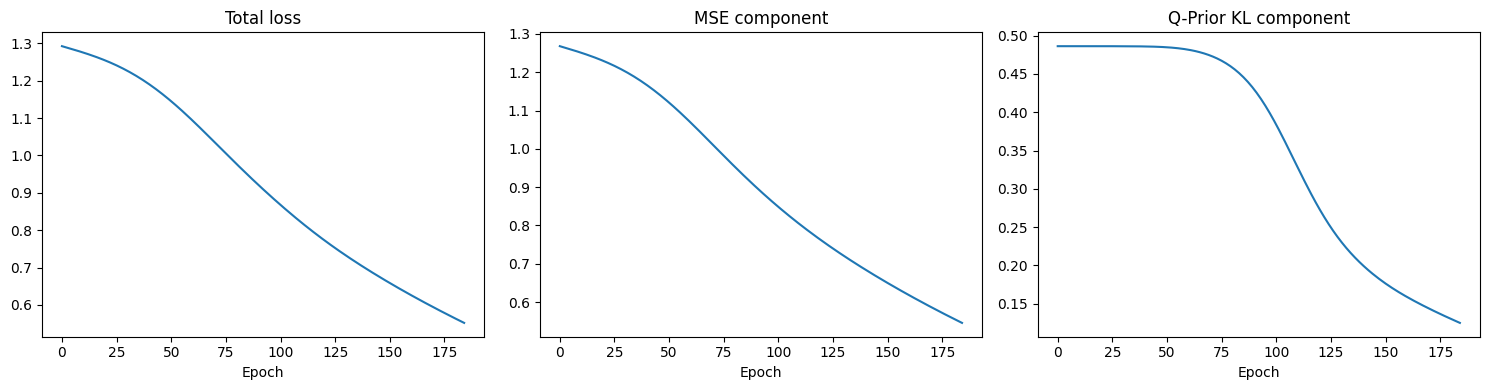

In [19]:

# Inspect training curves for the Q-Prior model

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(qprior_loss_history)
axes[0].set_title("Total loss")
axes[0].set_xlabel("Epoch")

axes[1].plot(qprior_mse_history)
axes[1].set_title("MSE component")
axes[1].set_xlabel("Epoch")

axes[2].plot(qprior_kl_history)
axes[2].set_title("Q-Prior KL component")
axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.show()


In [20]:

# Compare rating distributions: train empirical, Q-Prior, and SVD predictions

with torch.no_grad():
    mse_train_preds = model(train_users, train_movies)
    mse_train_dist = soft_rating_distribution(mse_train_preds, temperature=temperature).cpu().numpy()

    qprior_train_preds = model_qprior(train_users, train_movies)
    qprior_train_dist = soft_rating_distribution(qprior_train_preds, temperature=temperature).cpu().numpy()

train_counts = train_df["rating"].value_counts().sort_index().reindex([1, 2, 3, 4, 5], fill_value=0).values.astype(np.float32)
train_empirical_dist = train_counts / train_counts.sum()

dist_compare = pd.DataFrame({
    "rating": np.arange(1, 6),
    "train_empirical": train_empirical_dist,
    "learned_qprior": rating_qprior_np,
    "svd_mse_pred_dist": mse_train_dist,
    "svd_qprior_pred_dist": qprior_train_dist,
})

dist_compare


,rating,train_empirical,learned_qprior,svd_mse_pred_dist,svd_qprior_pred_dist
0,1,0.060938,0.061093,0.004751,0.005417
1,2,0.114212,0.113705,0.083570,0.086538
2,3,0.270038,0.271458,0.352122,0.345481
3,4,0.342275,0.341730,0.476894,0.473604
4,5,0.212537,0.212015,0.082663,0.088960


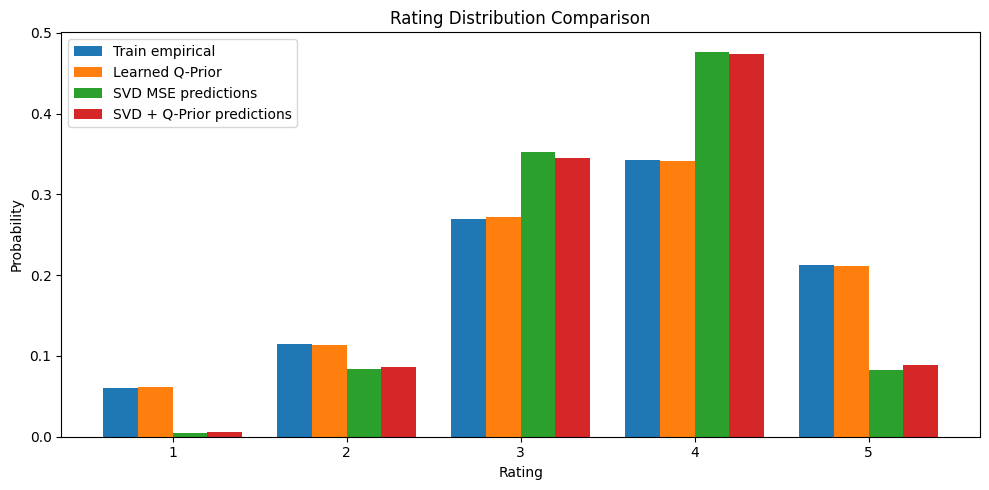

In [21]:

x = np.arange(1, 6)
width = 0.2

plt.figure(figsize=(10, 5))
plt.bar(x - 1.5 * width, train_empirical_dist, width=width, label="Train empirical")
plt.bar(x - 0.5 * width, rating_qprior_np, width=width, label="Learned Q-Prior")
plt.bar(x + 0.5 * width, mse_train_dist, width=width, label="SVD MSE predictions")
plt.bar(x + 1.5 * width, qprior_train_dist, width=width, label="SVD + Q-Prior predictions")

plt.xlabel("Rating")
plt.ylabel("Probability")
plt.title("Rating Distribution Comparison")
plt.xticks(x)
plt.legend()
plt.tight_layout()
plt.show()


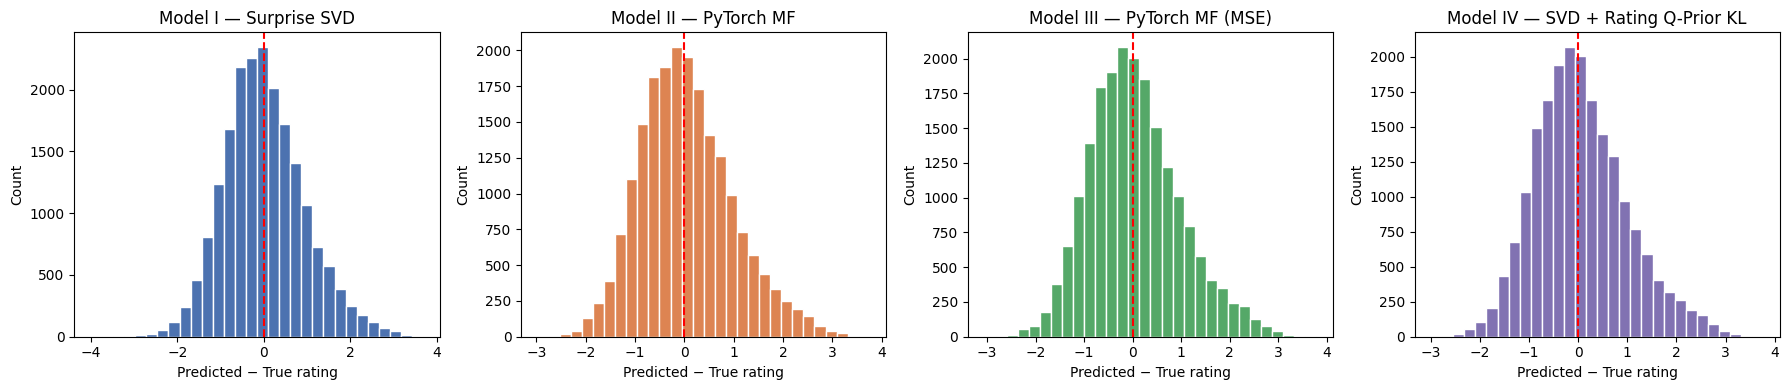

In [22]:

# Error distribution comparison including Model IV

qprior_errors = (qprior_test_preds - test_ratings).detach().cpu().numpy()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, errors, title, color in zip(
    axes,
    [pred_df["error"].values, pt_errors, mse_errors, qprior_errors],
    [
        "Model I — Surprise SVD",
        "Model II — PyTorch MF",
        "Model III — PyTorch MF (MSE)",
        "Model IV — SVD + Rating Q-Prior KL",
    ],
    ["#4C72B0", "#DD8452", "#55A868", "#8172B2"]
):
    ax.hist(errors, bins=30, color=color, edgecolor="white")
    ax.axvline(0, color="red", linestyle="--")
    ax.set_xlabel("Predicted − True rating")
    ax.set_ylabel("Count")
    ax.set_title(title)

plt.tight_layout()
plt.show()


---
## V — Prediction as probability
Softmax (predictions)


In [23]:
model_pytorch.eval()

n_movies = len(movie_to_idx)
movie_ids = torch.arange(n_movies)
all_probs = {}

with torch.no_grad():

    for user_idx in test_df["user_idx"].unique():

        users = torch.full(
            (n_movies,),
            user_idx,
            dtype=torch.long
        )

        scores = model_pytorch(users, movie_ids)

        probs = torch.softmax(scores, dim=0)

        all_probs[user_idx] = probs.cpu()

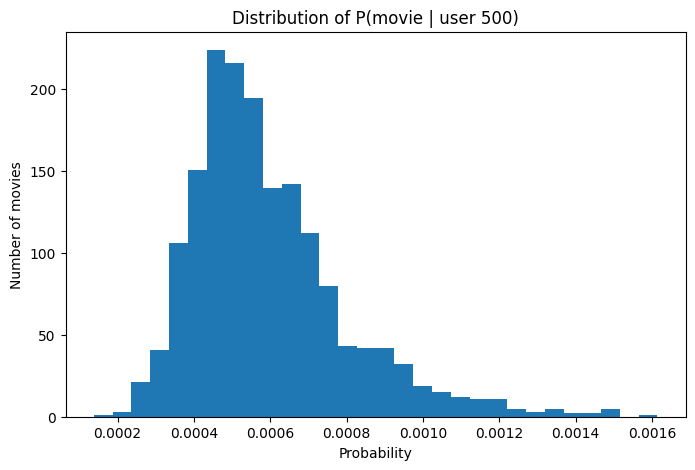

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(
    all_probs[500].numpy(),
    bins=30
)

plt.xlabel("Probability")
plt.ylabel("Number of movies")
plt.title(f"Distribution of P(movie | user {500})")

plt.show()


## Improvements ( To Do => SVD ++)